# YSL Sub-Cluster Analysis

## Environment Setup

Install software from pip, apt, and Github.  Load modules, configure workspace settings.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Environment Setup: everything now handled inside zmap-tools
#!pip -q install "git+https://github.com/WagnerLabUCSF/zmap-tools.git"
!pip install zmap-tools sctoolsrna

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc
import zmap
import scToolsRNA as sct

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 7.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 41.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.1/102.1 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.1/176.1 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 83.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 111.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 99.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 85.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.0/54.0 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 53.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 145.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━

In [ ]:
!pip list

Package                               Version
------------------------------------- ------------------
absl-py                               1.4.0
accelerate                            1.14.0
access                                1.1.10.post3
adjustText                            1.4.0
affine                                2.4.0
aiofiles                              25.1.0
aiohappyeyeballs                      2.7.1
aiohttp                               3.14.1
aiosignal                             1.4.0
aiosqlite                             0.22.1
alabaster                             1.0.0
albucore                              0.0.24
albumentations                        2.0.8
ale-py                                0.12.0
altair                                5.5.0
anndata                               0.12.18
annotated-doc                         0.0.4
annotated-types                       0.7.0
annoy                                 1.17.3
antlr4-python3-runtime                4.9.3
a

In [ ]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Load h5ad

In [ ]:
base_path='/content/drive/MyDrive/Colab Notebooks/Haley/YSL/'

In [ ]:
adata_full = sc.read(base_path+'YSL-full_pp_norm_processed.h5ad')

## Subset to YSL

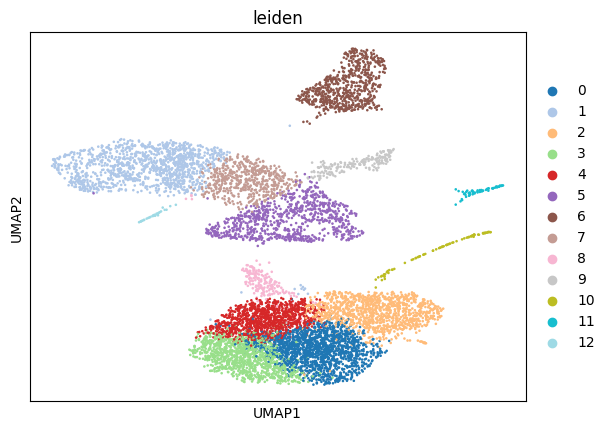

In [ ]:
sc.pl.umap(adata_full, color=['leiden'])

In [ ]:
# Subset to just the YSL cluster
adata = adata_full[adata_full.obs['leiden'].isin(['0','2','4','3'])]
adata

In [ ]:
# Save YSL subset adata
adata.write(base_path+'YSL-subset_pp_norm.h5ad')

## Perform Leiden clustering

In [ ]:
sc.tl.leiden(adata, resolution=0.25)

/tmp/ipykernel_213/3738871363.py:1: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=0.25)


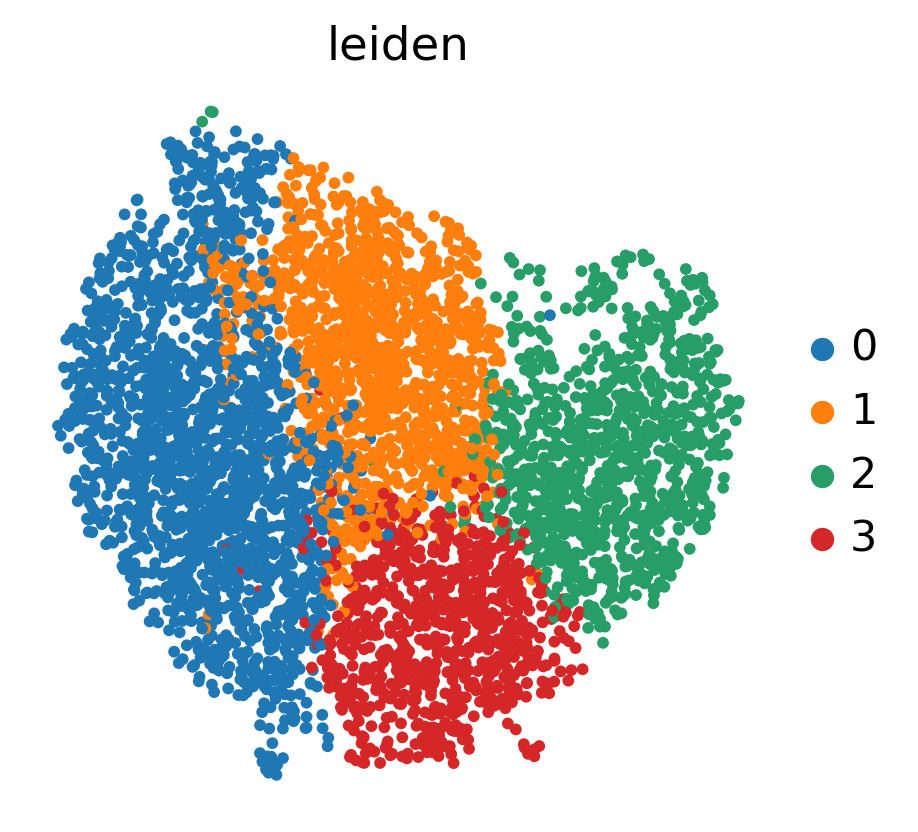

In [ ]:
sc.set_figure_params(figsize=(4, 4), dpi=120)

f1 = sc.pl.umap(adata, color=['leiden'], frameon=False, s=50, return_fig=True)

f1.savefig(base_path+'figs/'+'YSL_subset_leiden.png', dpi=200, bbox_inches="tight")


## RankGenesGroups: Leiden

In [ ]:
#sc.tl.rank_genes_groups(adata, 'leiden', method='wilcoxon')
sc.set_figure_params(figsize=(8, 8), dpi=120)
sc.pl.rank_genes_groups_dotplot(adata,
                                     n_genes=10,
                                     cmap='Blues',
                                     standard_scale='var',
                                     dendrogram=False,
                                     swap_axes=True,
                                     figsize=(3.8, 12),   # width, height
                                     return_fig=True)

f1.savefig(base_path+'figs/'+'YSL_subset_leiden_dotplot.pdf', dpi=200, bbox_inches="tight")

In [ ]:
import pandas as pd
import scanpy as sc

top_x = 50

groups = adata.uns["rank_genes_groups"]["names"].dtype.names

top_genes_df = pd.DataFrame({
    group: sc.get.rank_genes_groups_df(adata, group=group).head(top_x)["names"].values
    for group in groups
})

top_genes_df

,0,1,2,3
0,plekhg5b,tcf7l1a,fn1a,pcxb
1,LOC110437758,ntrk2a,lztfl1,pde4a
2,spred2b,col14a1a,zgc:112994,arhgap24
3,rmdn2,inpp4b,lamc1,tbx3a
4,baz2ba,si:dkey-172j4.3,bmp16,daam1a
5,lrrfip1b,slc7a8a,ror1,map7d2b
6,neurl1b,sulf1,mecom,lrba
7,mpp1,grb10b,eya1,tpk1
8,tspan18b,ednraa,lmo1,mthfd1b
9,trak1a,acp5a,rap1gap,fabp2


In [ ]:
import pandas as pd
import scanpy as sc

groups = adata.uns["rank_genes_groups"]["names"].dtype.names

deg_sig_df = pd.concat(
    [
        sc.get.rank_genes_groups_df(adata, group=group)
        .query("pvals_adj < 0.05 and logfoldchanges > 1")
        .sort_values("logfoldchanges", ascending=False)
        .assign(cell_type=group, rank=lambda df: range(1, len(df) + 1))
        for group in groups
    ],
ignore_index=True)

deg_sig_df = deg_sig_df.rename(
    columns={
        "names": "gene",
        "logfoldchanges": "log2fc",
        "pvals_adj": "adjusted_pvalue",
    }
)[["cell_type", "rank", "gene", "log2fc", "adjusted_pvalue"]]

deg_sig_df.to_csv("significant_enriched_DEGs_per_subcluster.csv", index=False)

deg_sig_df

,cell_type,rank,gene,log2fc,adjusted_pvalue
0,0,1,plekhg5b,4.974220,0.000000e+00
1,0,2,lrrfip1b,4.529852,2.371986e-205
2,0,3,rmdn2,4.276650,2.426831e-228
3,0,4,nfic,4.119599,3.095333e-134
4,0,5,tspan18b,4.056397,7.217559e-165
...,...,...,...,...,...
1757,3,243,igsf21a,1.009014,4.249266e-03
1758,3,244,adcy2a,1.008740,2.480059e-05
1759,3,245,si:ch211-212o1.2,1.006859,1.914767e-04
1760,3,246,flad1,1.006790,3.524304e-05


In [ ]:
import pandas as pd
import scanpy as sc

groups = adata.uns["rank_genes_groups"]["names"].dtype.names

deg_sig_df_depleted = pd.concat(
    [
        sc.get.rank_genes_groups_df(adata, group=group)
        .query("pvals_adj < 0.05 and logfoldchanges < -1")
        .sort_values("logfoldchanges", ascending=True)
        .assign(cell_type=group, rank=lambda df: range(1, len(df) + 1))
        for group in groups
    ],
    ignore_index=True,
)

deg_sig_df_depleted = deg_sig_df_depleted.rename(
    columns={
        "names": "gene",
        "logfoldchanges": "log2fc",
        "pvals_adj": "adjusted_pvalue",
    }
)[["cell_type", "rank", "gene", "log2fc", "adjusted_pvalue"]]

deg_sig_df_depleted.to_csv("significant_depleted_DEGs_per_subcluster.csv", index=False)

deg_sig_df_depleted

,cell_type,rank,gene,log2fc,adjusted_pvalue
0,0,1,bmp16,-4.370885,3.734643e-94
1,0,2,adora1b,-3.478127,6.649386e-11
2,0,3,fn1a,-3.256351,8.932972e-121
3,0,4,lmo1,-3.198595,1.507802e-101
4,0,5,kng1,-3.038217,3.437563e-87
...,...,...,...,...,...
1599,3,348,zgc:114173,-1.003251,1.867397e-02
1600,3,349,mrtfba,-1.001401,1.490359e-03
1601,3,350,sik2b,-1.001197,6.895384e-07
1602,3,351,glis1a,-1.000901,4.449043e-04


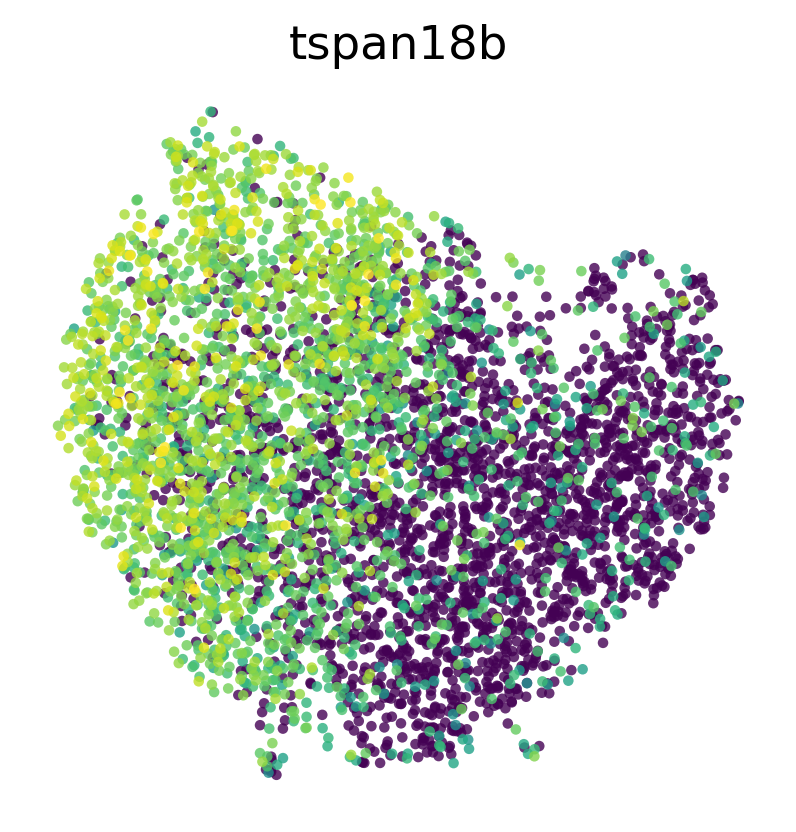

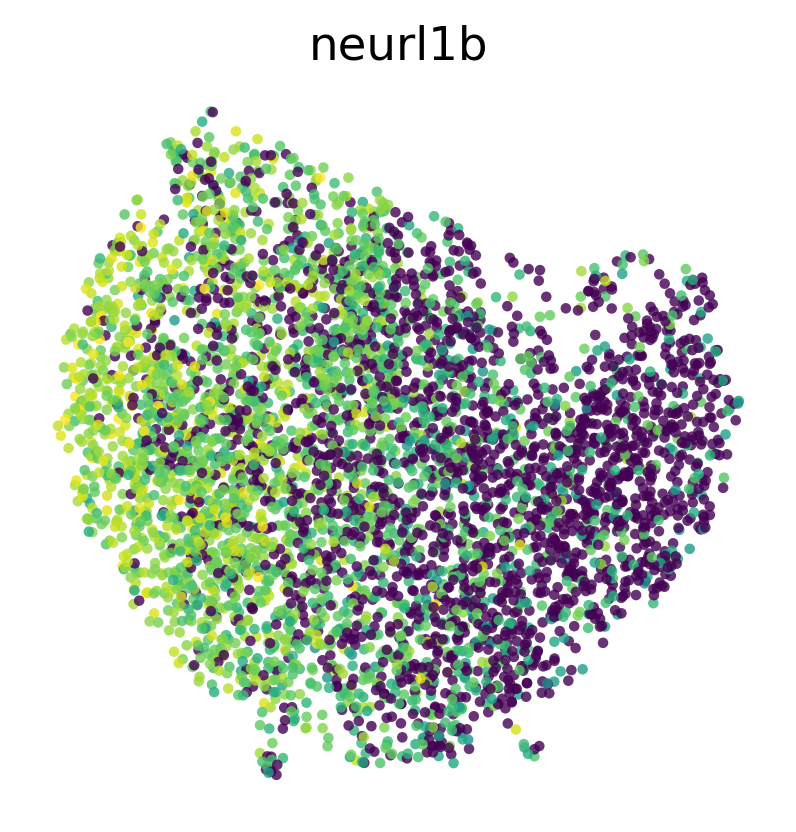

In [ ]:
from matplotlib import colorbar
sc.set_figure_params(figsize=(4, 4), dpi=120)
vmax=8
cmap=None

gene_name = 'tspan18b'
f=sc.pl.umap(adata, s=40, color=[gene_name], layer='tpm', frameon=False, vmax=vmax, return_fig=True, cmap=cmap, colorbar_loc=None, sort_order=True, alpha=0.8)
f.savefig(base_path+'figs/'+'YSL_subset_'+gene_name+'.png', dpi=200, bbox_inches="tight")

gene_name = 'neurl1b'
f=sc.pl.umap(adata, s=40, color=[gene_name], layer='tpm', frameon=False, vmax=vmax, return_fig=True, cmap=cmap, colorbar_loc=None, sort_order=False, alpha=0.8)
f.savefig(base_path+'figs/'+'YSL_subset_'+gene_name+'.png', dpi=200, bbox_inches="tight")


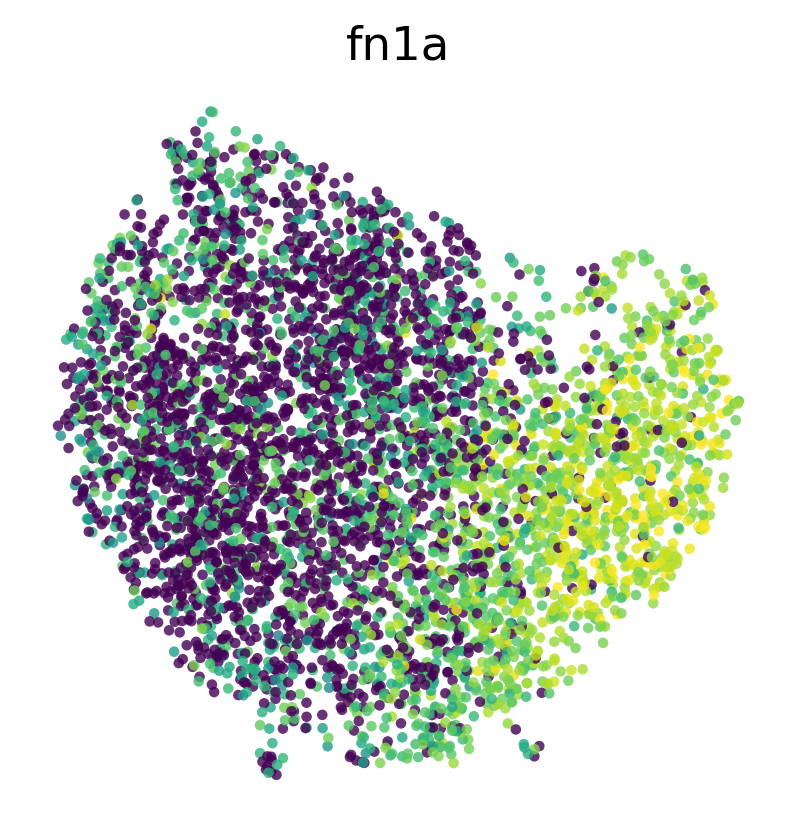

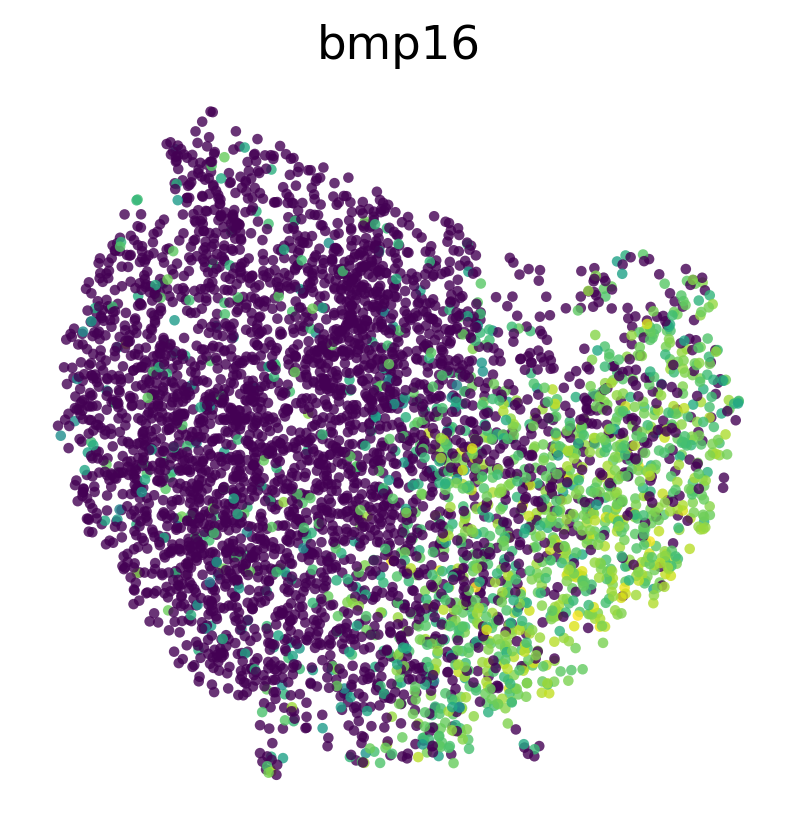

In [ ]:
from matplotlib import colorbar
sc.set_figure_params(figsize=(4, 4), dpi=120)
vmax=8

gene_name = 'fn1a'
f=sc.pl.umap(adata, s=40, color=[gene_name], layer='tpm', frameon=False, vmax=vmax, return_fig=True, colorbar_loc=None, sort_order=False, alpha=0.8)
f.savefig(base_path+'figs/'+'YSL_subset_'+gene_name+'.png', dpi=200, bbox_inches="tight")

gene_name = 'bmp16'
f=sc.pl.umap(adata, s=40, color=[gene_name], layer='tpm', frameon=False, vmax=vmax, return_fig=True, colorbar_loc=None, sort_order=False, alpha=0.8)
f.savefig(base_path+'figs/'+'YSL_subset_'+gene_name+'.png', dpi=200, bbox_inches="tight")

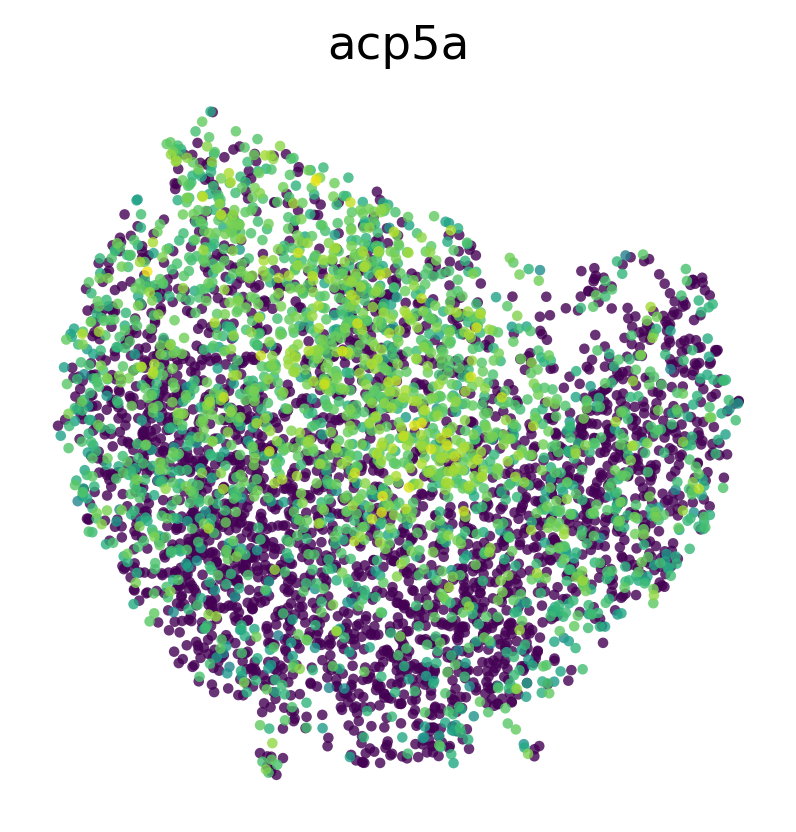

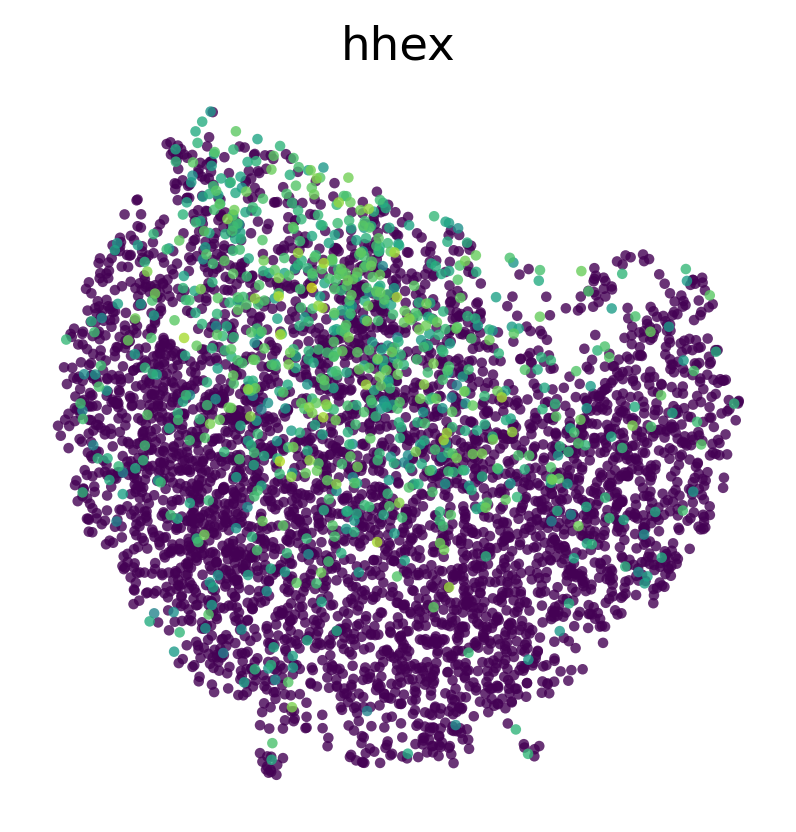

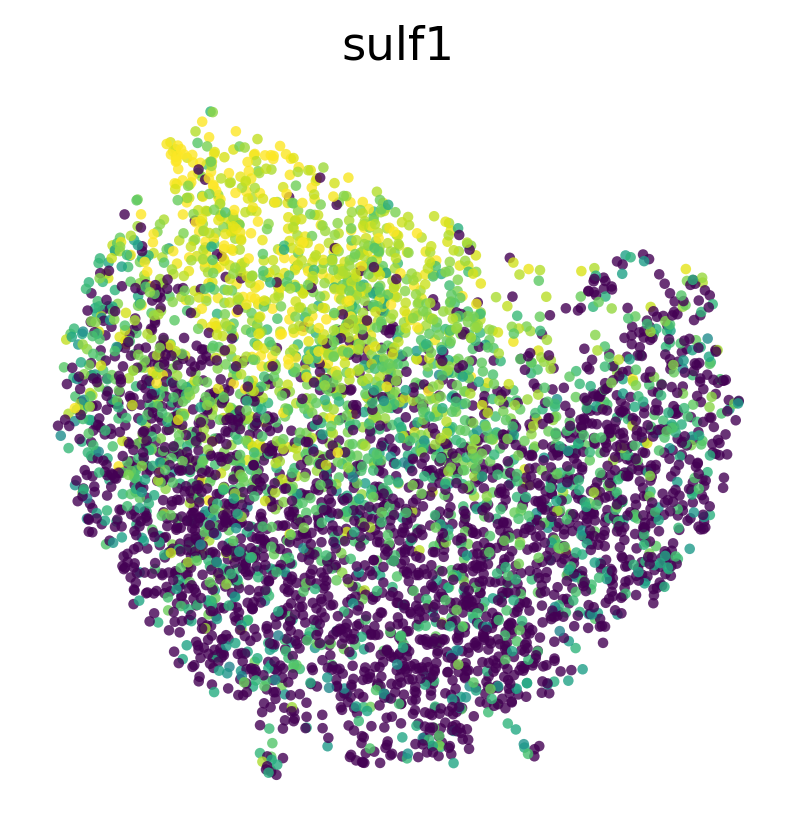

In [ ]:
from matplotlib import colorbar
sc.set_figure_params(figsize=(4, 4), dpi=120)
vmax=8

gene_name = 'acp5a'
f=sc.pl.umap(adata, s=40, color=[gene_name], layer='tpm', frameon=False, vmax=vmax, return_fig=True, colorbar_loc=None, sort_order=True, alpha=0.8)
f.savefig(base_path+'figs/'+'YSL_subset_'+gene_name+'.png', dpi=200, bbox_inches="tight")

gene_name = 'hhex'
f=sc.pl.umap(adata, s=40, color=[gene_name], layer='tpm', frameon=False, vmax=vmax, return_fig=True, colorbar_loc=None, sort_order=True, alpha=0.8)
f.savefig(base_path+'figs/'+'YSL_subset_'+gene_name+'.png', dpi=200, bbox_inches="tight")

gene_name = 'sulf1'
f=sc.pl.umap(adata, s=40, color=[gene_name], layer='tpm', frameon=False, vmax=vmax, return_fig=True, colorbar_loc=None, sort_order=False, alpha=0.8)
f.savefig(base_path+'figs/'+'YSL_subset_'+gene_name+'.png', dpi=200, bbox_inches="tight")

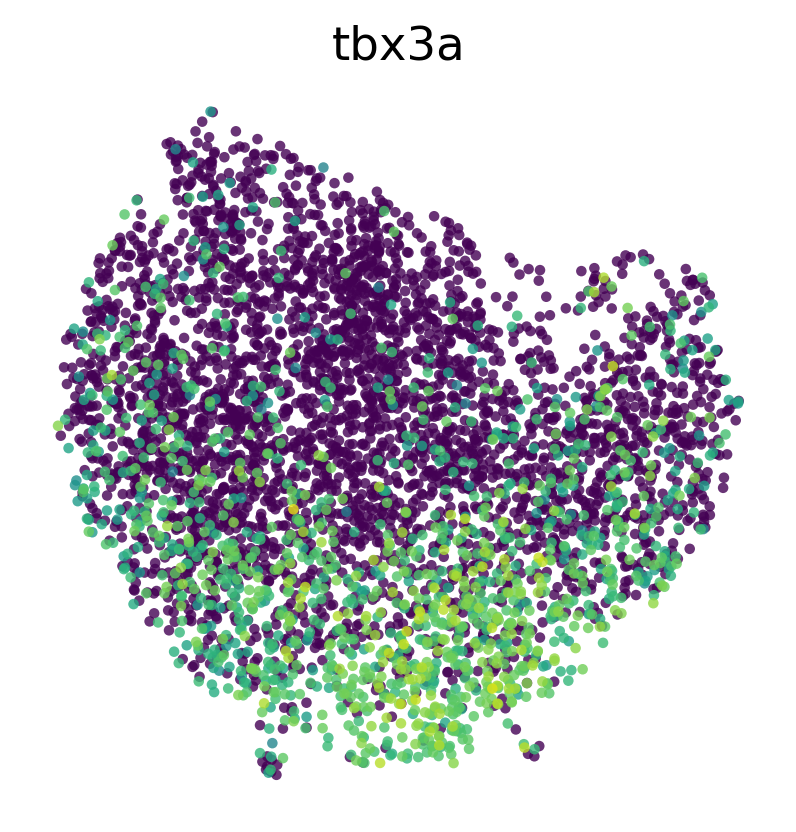

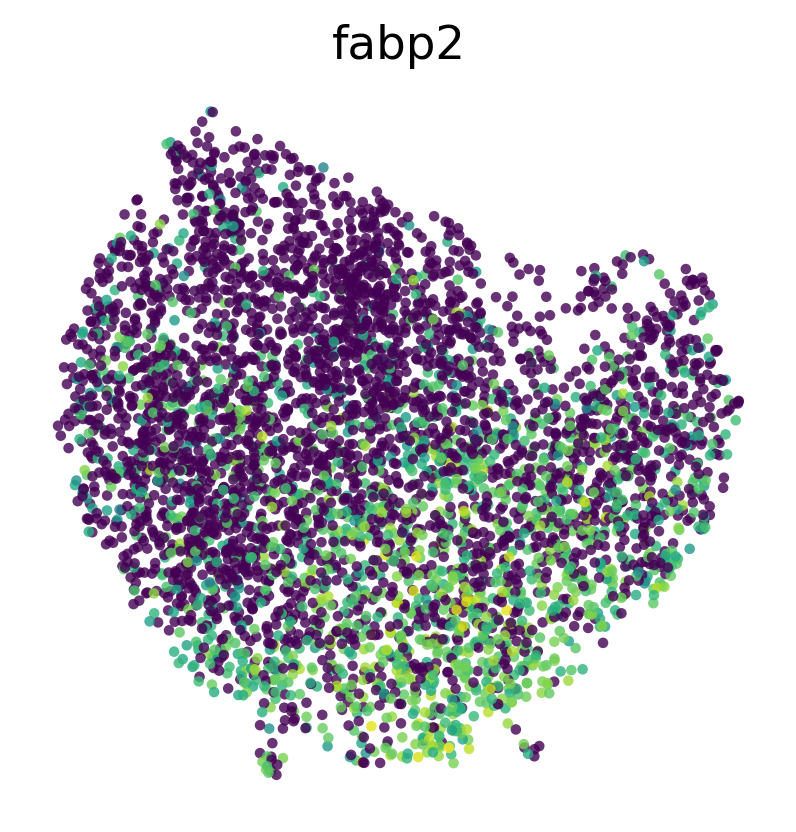

In [ ]:
from matplotlib import colorbar
sc.set_figure_params(figsize=(4, 4), dpi=120)
vmax=8

gene_name = 'tbx3a'
f=sc.pl.umap(adata, s=40, color=[gene_name], layer='tpm', frameon=False, vmax=vmax, return_fig=True, colorbar_loc=None, sort_order=True, alpha=0.8)
f.savefig(base_path+'figs/'+'YSL_subset_'+gene_name+'.png', dpi=200, bbox_inches="tight")

gene_name = 'fabp2'
f=sc.pl.umap(adata, s=40, color=[gene_name], layer='tpm', frameon=False, vmax=vmax, return_fig=True, colorbar_loc=None, sort_order=False, alpha=0.8)
f.savefig(base_path+'figs/'+'YSL_subset_'+gene_name+'.png', dpi=200, bbox_inches="tight")


## Dotplots: Leiden

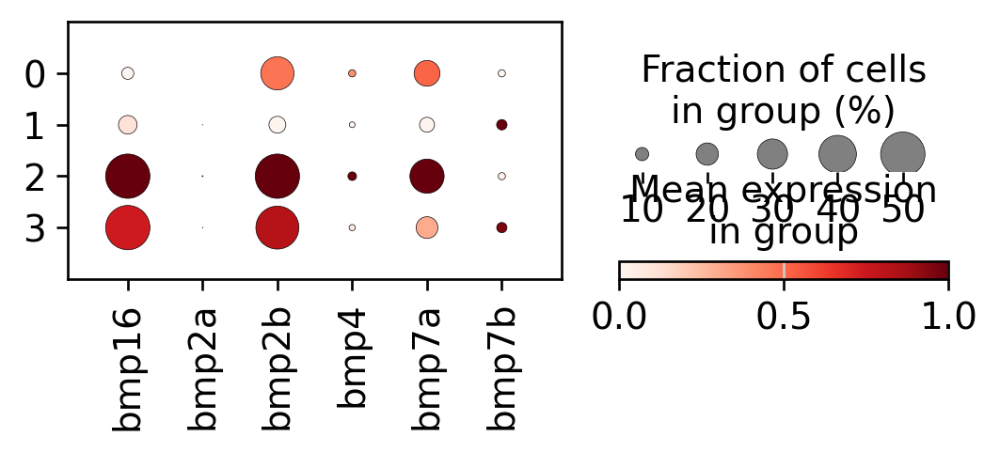

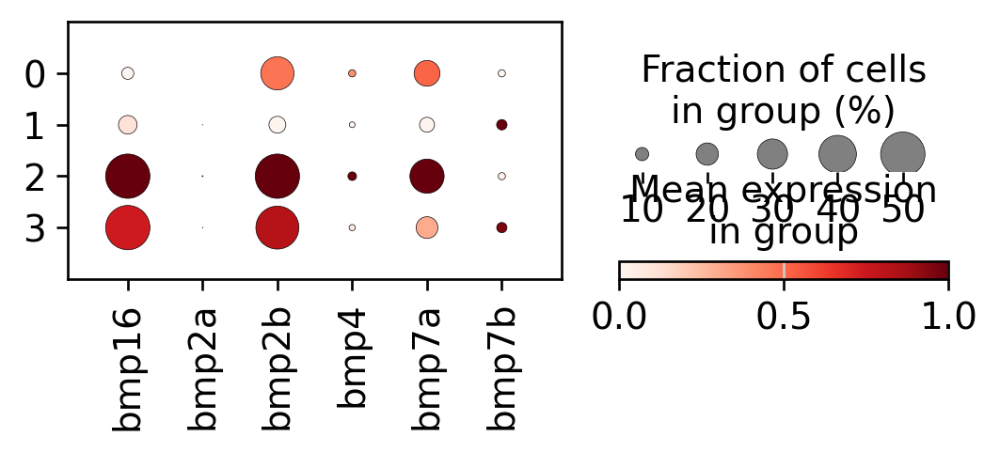

In [ ]:

sc.set_figure_params(figsize=(8, 8), dpi=120)

f1 = sc.pl.dotplot(adata,
                   var_names=['bmp16','bmp2a','bmp2b','bmp4','bmp7a','bmp7b'],
                   groupby='leiden',
                   cmap='Reds',
                   standard_scale='var',
                   dendrogram=False,
                   dot_min=0,
                   dot_max=0.5,
                   swap_axes=False,
                   figsize=(5, 1.5),   # width, height
                   return_fig=True)

f1.savefig(base_path+'figs/'+'YSL_subset_leiden_dotplot_bmps.pdf', dpi=200, bbox_inches="tight")
f1.savefig(base_path+'figs/'+'YSL_subset_leiden_dotplot_bmps.png', dpi=200, bbox_inches="tight")


## Install cNMF

In [ ]:
!pip -q install cnmf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 16.5 MB/s eta 0:00:00


## Initial cNMF runs (k scan, 50 iterations)

In [ ]:
# Prepare subsampled h5ad for testing
adata.X = adata.layers['raw_nolog'].copy()
adata.write_h5ad(base_path+'/nmf/cnmf_counts.h5ad')

In [ ]:
# Initiate cNMF object

from cnmf import cNMF

cnmf_obj = cNMF(output_dir=base_path+'/nmf/cnmf_out', name='HS_YSL_sub_4')

In [ ]:
# Prepare cNMF run

cnmf_obj.prepare(counts_fn=base_path+'/nmf/cnmf_counts.h5ad',
                 #components=[10, 20, 30, 40, 50, 60, 80, 100, 120],      #HS_YSL_sub
                 #components=[5,10,15,20,25,30,35,40,45,50],              #HS_YSL_sub_2
                 #components=[2,4,6,8,10,12,14,16,18,20],                 #HS_YSL_sub_3
                 components=[2,4,6,8,10,12,14,16,18,20,22,24,26,28,30],   #HS_YSL_sub_4
                 n_iter=50,
                 seed=14,
                 num_highvar_genes=2000)


/usr/local/lib/python3.12/dist-packages/cnmf/cnmf.py:616: UserWarning: 750 runs already appear completed. If this is unexpected, consider
            re-initializing the cnmf object with a different run name or output directory
  warnings.warn(message, UserWarning)


In [ ]:
# Run parallel workers to factorize spectra

from cnmf import cNMF
from multiprocessing import Process

def run_worker(i):
    cnmf_obj = cNMF(output_dir=base_path+'/nmf/cnmf_out', name='HS_YSL_sub_4')
    cnmf_obj.factorize(worker_i=i, total_workers=16)

workers = []
for i in range(16):
    p = Process(target=run_worker, args=(i,))
    p.start()
    workers.append(p)

for p in workers:
    p.join()

[Worker 1]. Starting task 1.
[Worker 3]. Starting task 3.
[Worker 0]. Starting task 0.
[Worker 2]. Starting task 2.
[Worker 4]. Starting task 4.
[Worker 5]. Starting task 5.
[Worker 6]. Starting task 6.
[Worker 7]. Starting task 7.
[Worker 8]. Starting task 8.
[Worker 10]. Starting task 10.
[Worker 9]. Starting task 9.
[Worker 11]. Starting task 11.
[Worker 13]. Starting task 13.
[Worker 12]. Starting task 12.
[Worker 14]. Starting task 14.
[Worker 15]. Starting task 15.
[Worker 1]. Starting task 17.[Worker 0]. Starting task 16.

[Worker 3]. Starting task 19.
[Worker 2]. Starting task 18.
[Worker 7]. Starting task 23.
[Worker 5]. Starting task 21.[Worker 4]. Starting task 20.

[Worker 8]. Starting task 24.
[Worker 6]. Starting task 22.
[Worker 9]. Starting task 25.
[Worker 10]. Starting task 26.
[Worker 11]. Starting task 27.
[Worker 13]. Starting task 29.
[Worker 12]. Starting task 28.
[Worker 14]. Starting task 30.
[Worker 15]. Starting task 31.
[Worker 1]. Starting task 33.
[Worker 

/usr/local/lib/python3.12/dist-packages/sklearn/decomposition/_nmf.py:1742: ConvergenceWarning: Maximum number of iterations 1000 reached. Increase it to improve convergence.
  warnings.warn(


[Worker 4]. Starting task 244.
[Worker 13]. Starting task 253.
[Worker 1]. Starting task 273.
[Worker 12]. Starting task 252.
[Worker 2]. Starting task 258.
[Worker 6]. Starting task 246.
[Worker 3]. Starting task 259.
[Worker 9]. Starting task 249.
[Worker 10]. Starting task 282.
[Worker 8]. Starting task 296.
[Worker 0]. Starting task 272.
[Worker 12]. Starting task 268.
[Worker 7]. Starting task 295.
[Worker 2]. Starting task 274.
[Worker 14]. Starting task 286.
[Worker 9]. Starting task 265.
[Worker 11]. Starting task 283.
[Worker 13]. Starting task 269.
[Worker 15]. Starting task 271.
[Worker 12]. Starting task 284.
[Worker 3]. Starting task 275.
[Worker 4]. Starting task 260.
[Worker 5]. Starting task 261.
[Worker 2]. Starting task 290.
[Worker 9]. Starting task 281.
[Worker 13]. Starting task 285.
[Worker 15]. Starting task 287.
[Worker 7]. Starting task 311.
[Worker 1]. Starting task 289.
[Worker 10]. Starting task 298.
[Worker 8]. Starting task 312.
[Worker 4]. Starting task 2

/usr/local/lib/python3.12/dist-packages/sklearn/decomposition/_nmf.py:1742: ConvergenceWarning: Maximum number of iterations 1000 reached. Increase it to improve convergence.
  warnings.warn(


[Worker 9]. Starting task 313.
[Worker 4]. Starting task 340.
[Worker 5]. Starting task 325.
[Worker 8]. Starting task 344.
[Worker 1]. Starting task 337.
[Worker 7]. Starting task 359.
[Worker 10]. Starting task 346.
[Worker 0]. Starting task 336.
[Worker 12]. Starting task 332.
[Worker 13]. Starting task 333.
[Worker 15]. Starting task 335.
[Worker 6]. Starting task 310.
[Worker 5]. Starting task 341.
[Worker 11]. Starting task 331.
[Worker 1]. Starting task 353.
[Worker 4]. Starting task 356.
[Worker 0]. Starting task 352.
[Worker 14]. Starting task 350.
[Worker 11]. Starting task 347.
[Worker 7]. Starting task 375.
[Worker 5]. Starting task 357.
[Worker 3]. Starting task 323.
[Worker 15]. Starting task 351.
[Worker 0]. Starting task 368.
[Worker 8]. Starting task 360.
[Worker 9]. Starting task 329.
[Worker 10]. Starting task 362.


...

[Worker 11]. Starting task 651.
[Worker 13]. Starting task 685.
[Worker 4]. Starting task 692.
[Worker 0]. Starting task 704.
[Worker 7]. Starting task 679.
[Worker 11]. Starting task 667.
[Worker 3]. Starting task 691.
[Worker 5]. Starting task 725.
[Worker 12]. Starting task 652.
[Worker 14]. Starting task 686.
[Worker 6]. Starting task 646.
[Worker 8]. Starting task 728.
[Worker 10]. Starting task 666.
[Worker 1]. Starting task 657.
[Worker 0]. Starting task 720.
[Worker 7]. Starting task 695.
[Worker 6]. Starting task 662.
[Worker 3]. Starting task 707.
[Worker 8]. Starting task 744.
[Worker 2]. Starting task 690.
[Worker 11]. Starting task 683.
[Worker 12]. Starting task 668.
[Worker 15]. Starting task 671.
[Worker 4]. Starting task 708.
[Worker 1]. Starting task 673.
[Worker 9]. Starting task 665.
[Worker 14]. Starting task 702.
[Worker 3]. Starting task 723.
[Worker 15]. Starting task 687.
[Worker 13]. Starting task 701.
[Worker 1]. Starting task 689.
[Worker 5]. Starting task 7

/usr/local/lib/python3.12/dist-packages/sklearn/decomposition/_nmf.py:1742: ConvergenceWarning: Maximum number of iterations 1000 reached. Increase it to improve convergence.
  warnings.warn(


[Worker 9]. Starting task 697.


/usr/local/lib/python3.12/dist-packages/sklearn/decomposition/_nmf.py:1742: ConvergenceWarning: Maximum number of iterations 1000 reached. Increase it to improve convergence.
  warnings.warn(


[Worker 15]. Starting task 719.
[Worker 6]. Starting task 694.
[Worker 13]. Starting task 733.
[Worker 1]. Starting task 737.
[Worker 10]. Starting task 714.
[Worker 9]. Starting task 713.
[Worker 15]. Starting task 735.
[Worker 12]. Starting task 732.
[Worker 6]. Starting task 710.
[Worker 11]. Starting task 731.
[Worker 13]. Starting task 749.
[Worker 10]. Starting task 730.
[Worker 6]. Starting task 726.
[Worker 12]. Starting task 748.
[Worker 6]. Starting task 742.
[Worker 9]. Starting task 729.
[Worker 11]. Starting task 747.
[Worker 10]. Starting task 746.
[Worker 9]. Starting task 745.


Combining factorizations for k=2.
Combining factorizations for k=4.
Combining factorizations for k=6.
Combining factorizations for k=8.
Combining factorizations for k=10.
Combining factorizations for k=12.
Combining factorizations for k=14.
Combining factorizations for k=16.
Combining factorizations for k=18.
Combining factorizations for k=20.
Combining factorizations for k=22.
Combining factorizations for k=24.
Combining factorizations for k=26.
Combining factorizations for k=28.
Combining factorizations for k=30.


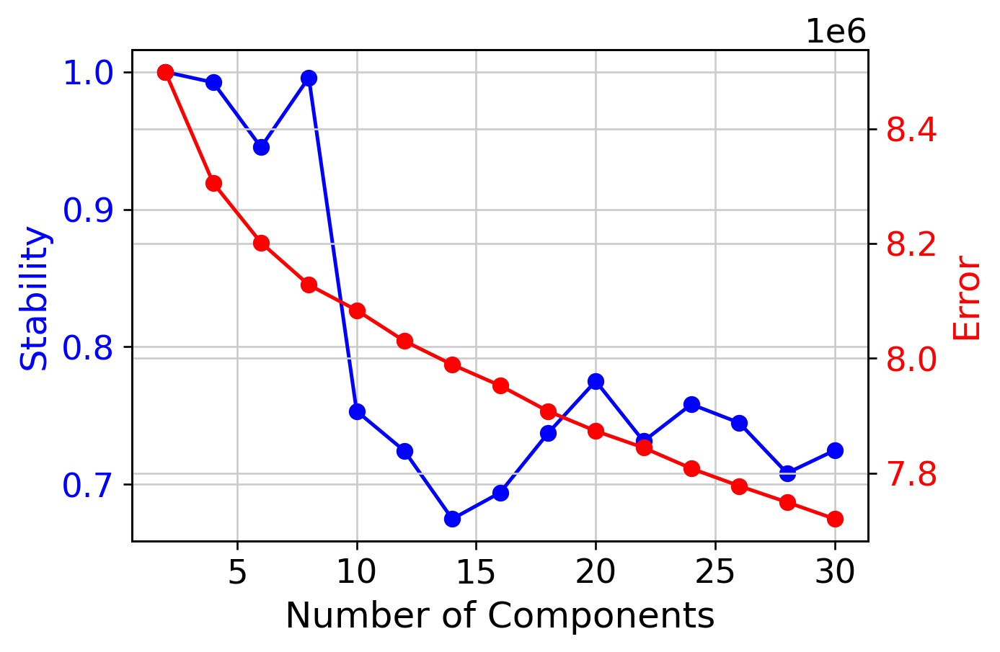

In [ ]:
# Combine spectra and inspect the k-selection plot
cnmf_obj.combine()
cnmf_obj.k_selection_plot()

# Inspect the 'K selection' plot
#from IPython.display import Image
#kselect_plot_path = ''
#Image(filename = kselect_plot_path, width=800, height=800)

## cNMF k=8 consensus

In [ ]:
from cnmf import cNMF
cnmf_obj = cNMF(output_dir=base_path+'/nmf/cnmf_out', name='HS_YSL_sub_4')

/usr/lib/python3.12/functools.py:912: UserWarning: Received a view of an AnnData. Making a copy.
  return dispatch(args[0].__class__)(*args, **kw)


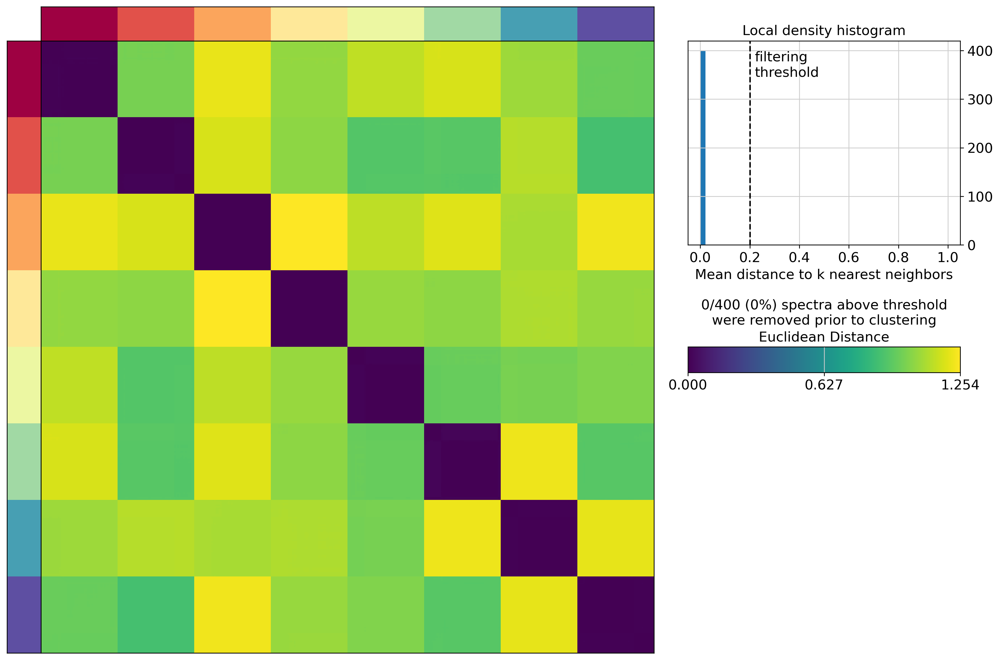

In [ ]:
# Generate consensus
k=8
density_threshold=0.2

cnmf_obj.consensus(k=k, density_threshold=density_threshold, show_clustering=True)

# Inspect the consensus plot
#consensus_plot_path = ''
#Image(filename = consensus_plot_path, width=800, height=600)

In [ ]:
# Load results
usage, spectra_scores, spectra_tpm, top_genes = cnmf_obj.load_results(K=k,density_threshold=density_threshold)

# Rename columns for clarity
usage.columns = ['GEP1','GEP2','GEP3','GEP4','GEP5','GEP6','GEP7','GEP8']
top_genes.columns = ['GEP1','GEP2','GEP3','GEP4','GEP5','GEP6','GEP7','GEP8']

# Import into adata
usage_aligned = usage.reindex(adata.obs_names)        # alignment to cell order in adata
adata.obsm["X_cnmf"] = usage_aligned.values           #
adata.obs[usage_aligned.columns] = usage_aligned      # per-topic columns in obs


In [ ]:
import pandas as pd
pd.set_option('display.max_columns', None)
top_genes.head(50)

,GEP1,GEP2,GEP3,GEP4,GEP5,GEP6,GEP7,GEP8
0,AL935186.9,baz2ba,col14a1a,arhgap24,ror1,adka,tll1,LOC101883431
1,si:dkey-207m2.4,st3gal3b,tcf7l1a,pde4a,ptprub,tmem56b,trip10a,LOC108180139
2,NC_002333.17,nfic,si:dkey-172j4.3,mthfd1b,jarid2b,diaph2,sulf1,LOC110437824
3,apoeb,abi1a,grb10b,daam1a,ctnnd2b,celf2,lrrfip1b,he1.3
4,NC_002333.4,fgf14,slc7a8a,ripor1-1,tas2r3,slc27a2a,kirrel3l,foxo3b
5,dusp19b,farp2,ntrk2a,pcxb,arhgef4,abcb11a,kif26ab,CR788316.2
6,rn7sk,eva1a,inpp4b,tpk1,stard13b,nrp1a,si:dkey-157l19.2,cadm2a
7,zgc:110425,kat5b,neo1a,bmp16,opcml,pcxb,tfec,XLOC_018363
8,apoa1b,stard8,ednraa,lamc1,mcf2l2,raraa,plxdc2,LOC100537178
9,spen,adarb1b,hsd20b2,ptprfb,fn1a,snx29,slco1e1,rbl2


In [ ]:
top_genes.to_csv(base_path+'figs/'+'8GEP_top100genes.csv')

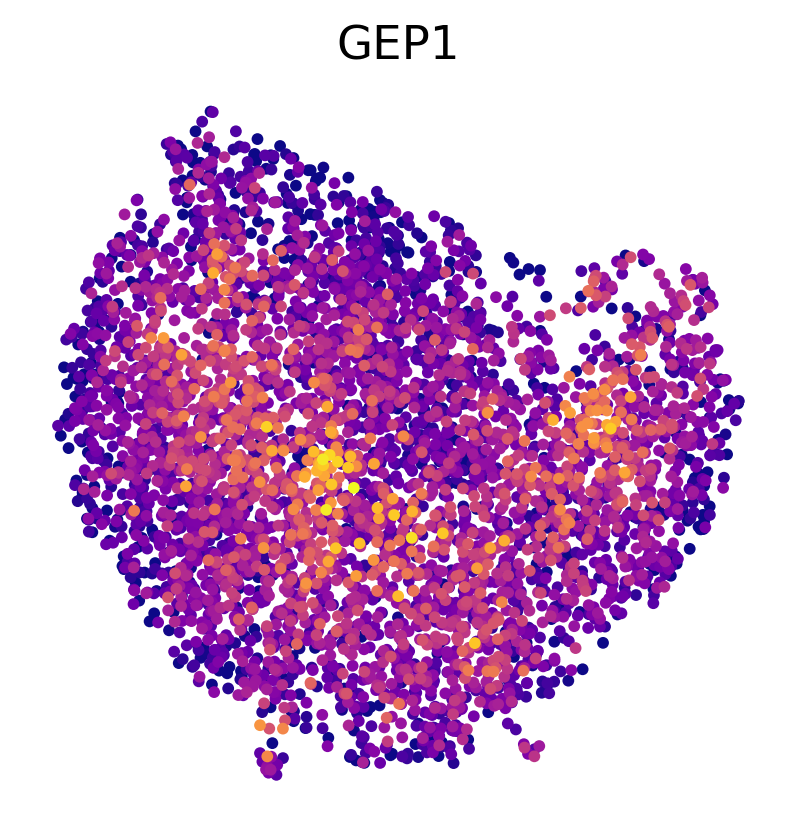

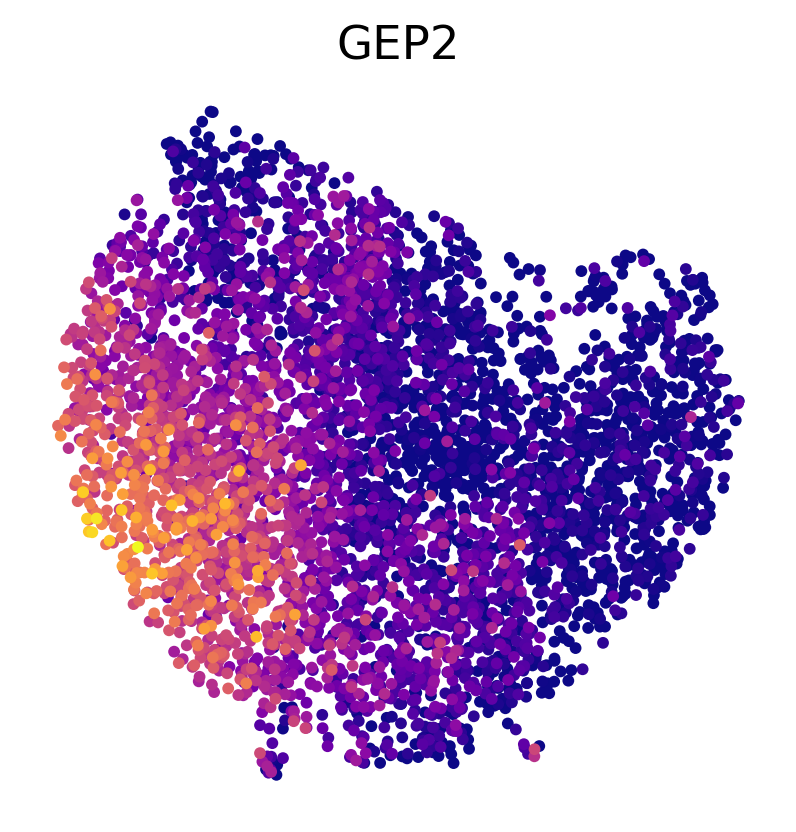

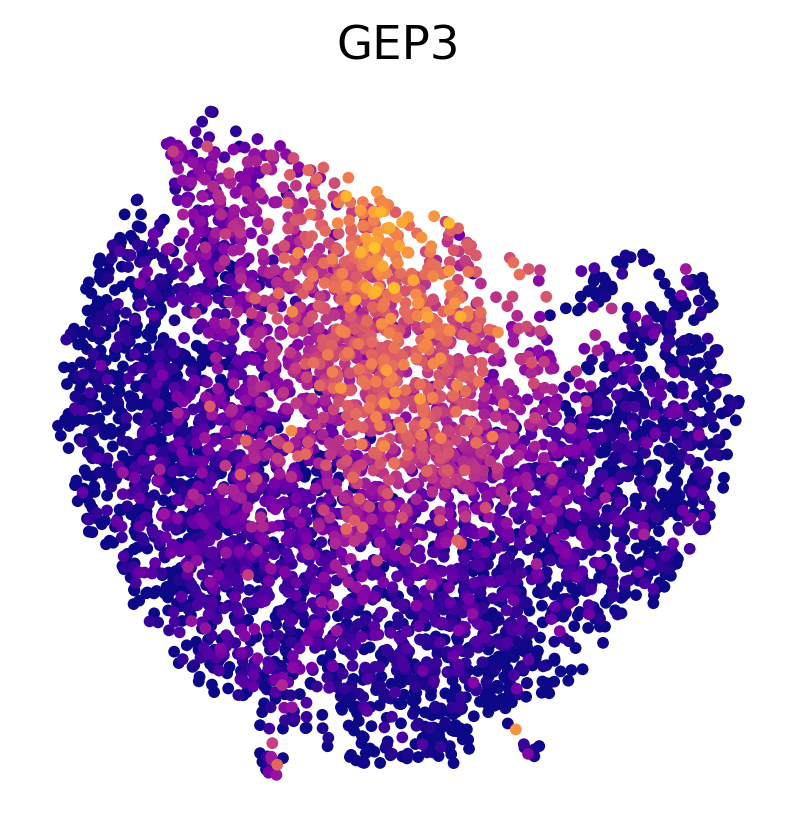

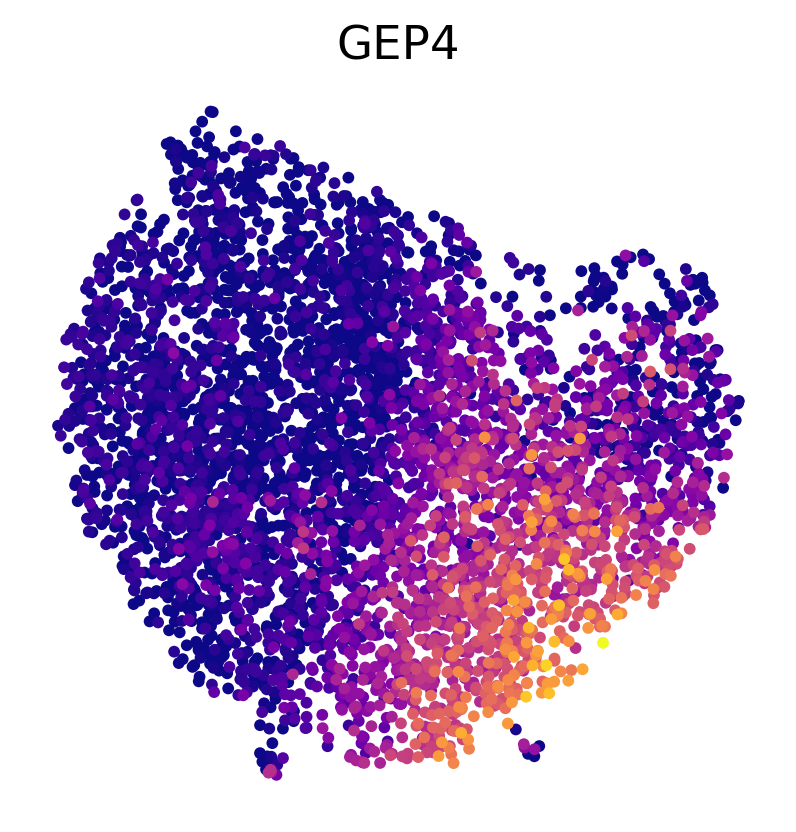

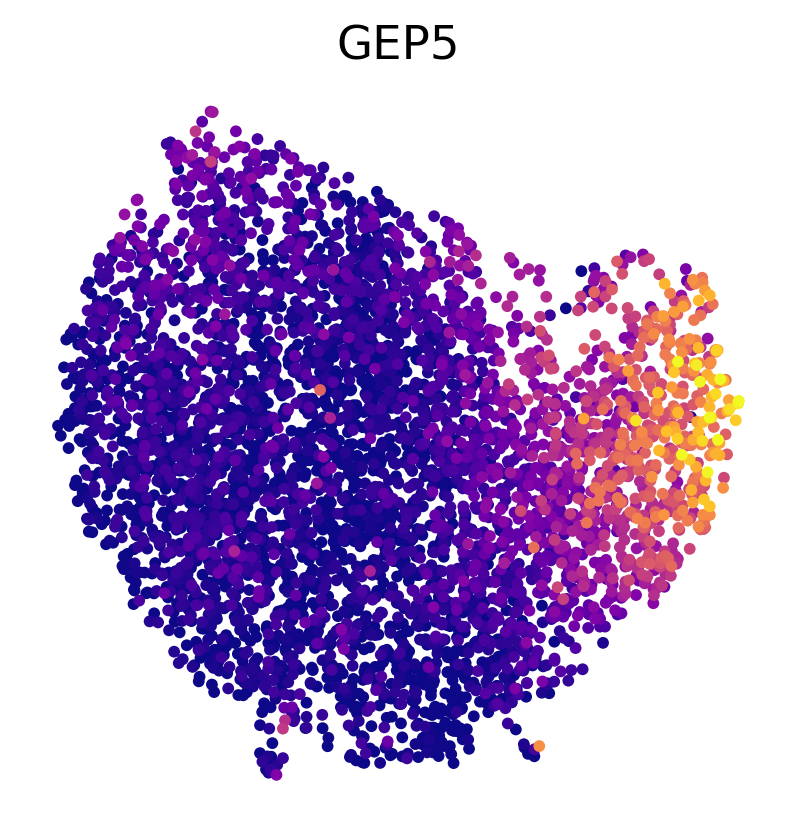

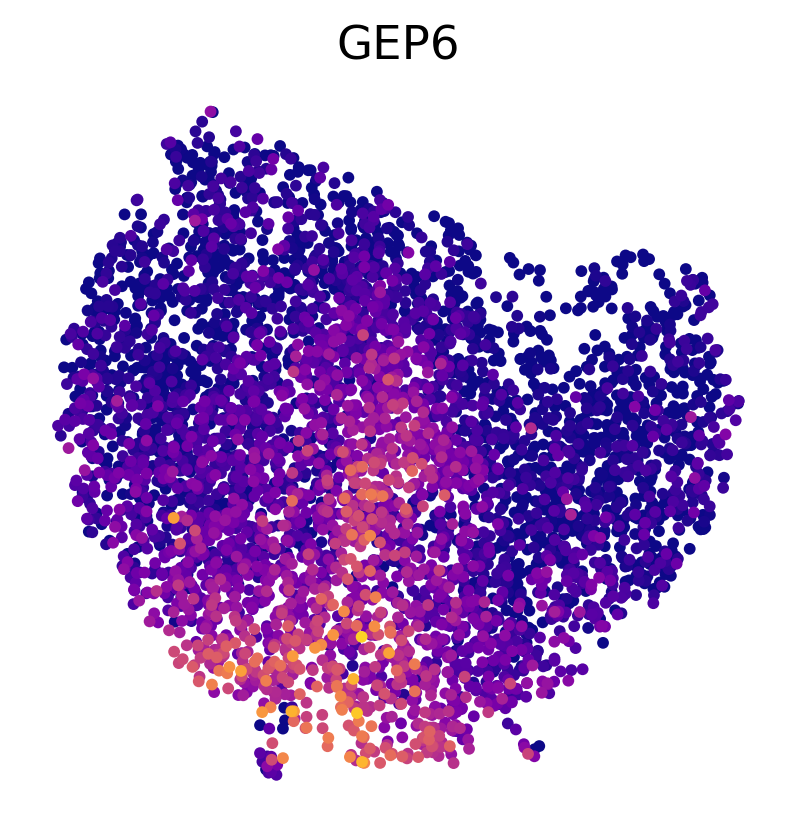

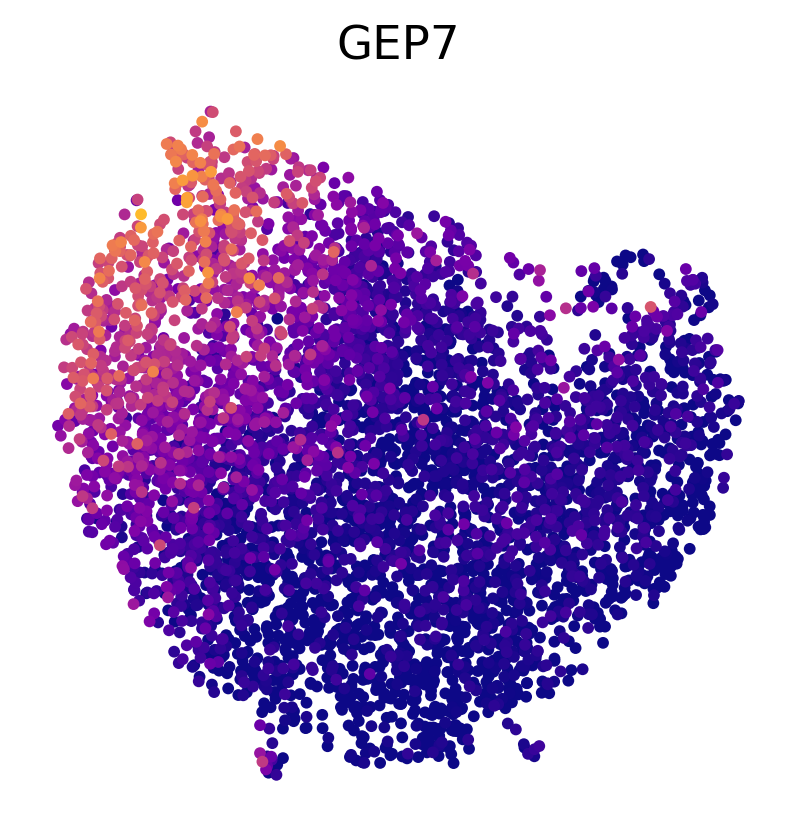

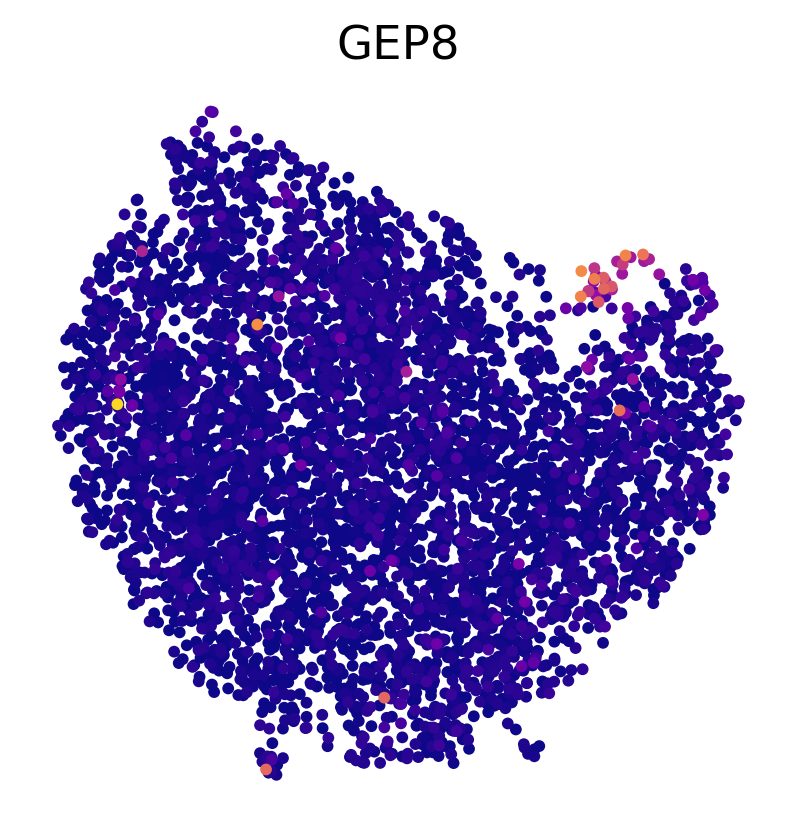

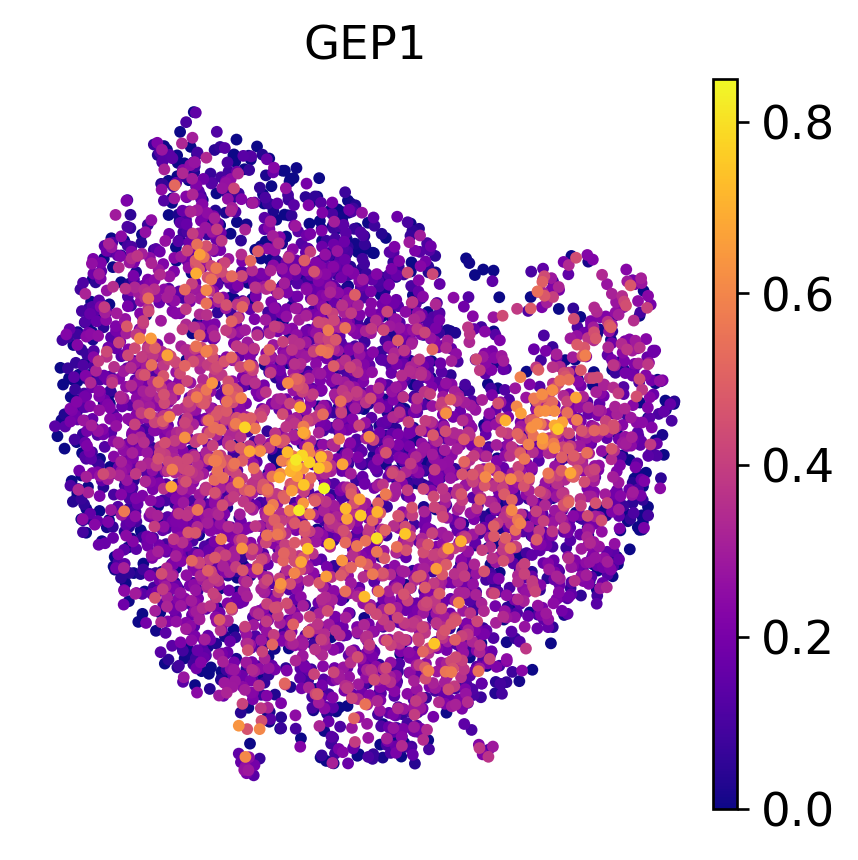

In [ ]:
sc.set_figure_params(figsize=(4, 4), dpi=120)
cmap='plasma'

f1 = sc.pl.umap(adata, s=50, frameon=False, color=['GEP1'], vmax=0.85, return_fig=True, cmap=cmap, colorbar_loc=None)
f2 = sc.pl.umap(adata, s=50, frameon=False, color=['GEP2'], vmax=0.85, return_fig=True, cmap=cmap, colorbar_loc=None)
f3 = sc.pl.umap(adata, s=50, frameon=False, color=['GEP3'], vmax=0.85, return_fig=True, cmap=cmap, colorbar_loc=None)
f4 = sc.pl.umap(adata, s=50, frameon=False, color=['GEP4'], vmax=0.85, return_fig=True, cmap=cmap, colorbar_loc=None)
f5 = sc.pl.umap(adata, s=50, frameon=False, color=['GEP5'], vmax=0.85, return_fig=True, cmap=cmap, colorbar_loc=None)
f6 = sc.pl.umap(adata, s=50, frameon=False, color=['GEP6'], vmax=0.85, return_fig=True, cmap=cmap, colorbar_loc=None)
f7 = sc.pl.umap(adata, s=50, frameon=False, color=['GEP7'], vmax=0.85, return_fig=True, cmap=cmap, colorbar_loc=None)
f8 = sc.pl.umap(adata, s=50, frameon=False, color=['GEP8'], vmax=0.85, return_fig=True, cmap=cmap, colorbar_loc=None)

f1.savefig(base_path+'figs/'+'YSL_subset_k8_GEP1.png', dpi=200, bbox_inches="tight")
f2.savefig(base_path+'figs/'+'YSL_subset_k8_GEP2.png', dpi=200, bbox_inches="tight")
f3.savefig(base_path+'figs/'+'YSL_subset_k8_GEP3.png', dpi=200, bbox_inches="tight")
f4.savefig(base_path+'figs/'+'YSL_subset_k8_GEP4.png', dpi=200, bbox_inches="tight")
f5.savefig(base_path+'figs/'+'YSL_subset_k8_GEP5.png', dpi=200, bbox_inches="tight")
f6.savefig(base_path+'figs/'+'YSL_subset_k8_GEP6.png', dpi=200, bbox_inches="tight")
f7.savefig(base_path+'figs/'+'YSL_subset_k8_GEP7.png', dpi=200, bbox_inches="tight")
f8.savefig(base_path+'figs/'+'YSL_subset_k8_GEP8.png', dpi=200, bbox_inches="tight")

f1 = sc.pl.umap(adata, s=50, frameon=False, color=['GEP1'], vmax=0.85, cmap=cmap, return_fig=True)




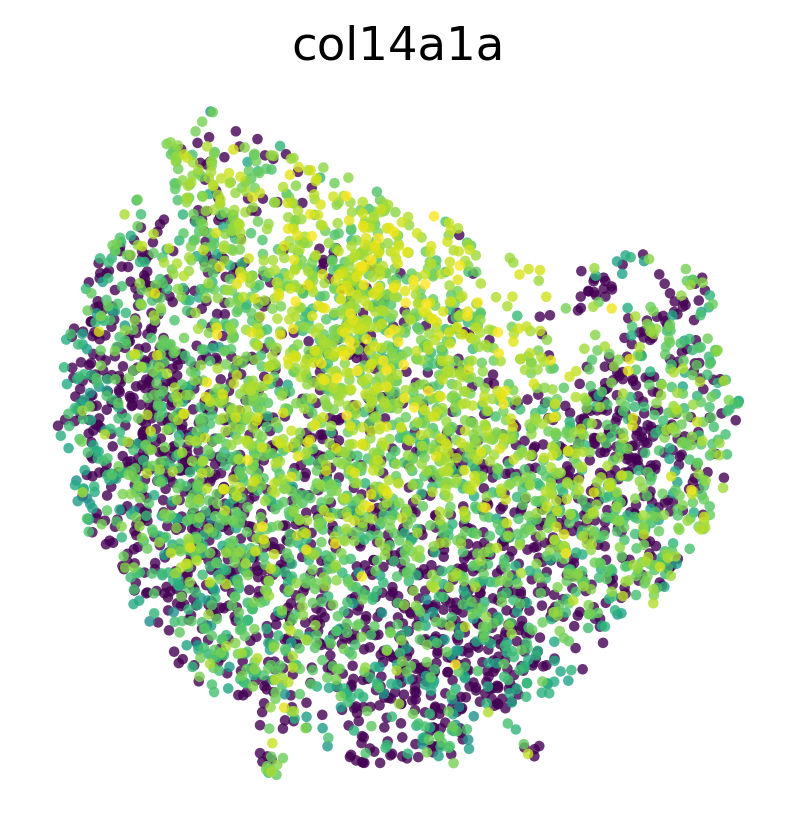

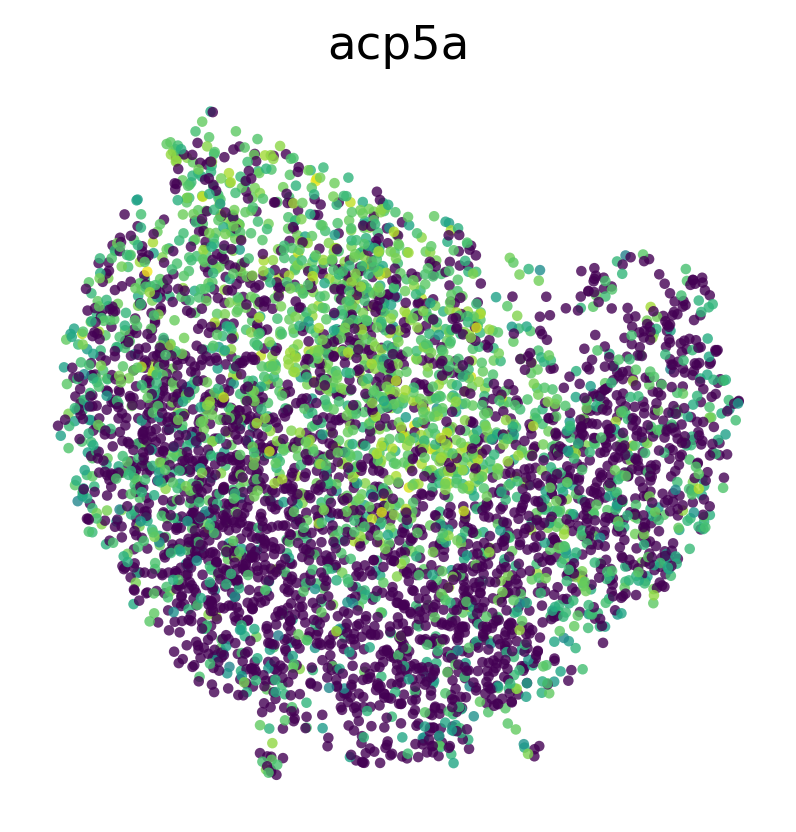

In [ ]:
from matplotlib import colorbar
sc.set_figure_params(figsize=(4, 4), dpi=120)
vmax=8

gene_name = 'col14a1a'
f=sc.pl.umap(adata, s=40, color=[gene_name], layer='tpm', frameon=False, vmax=vmax, return_fig=True, colorbar_loc=None, sort_order=True, alpha=0.8)
f.savefig(base_path+'figs/'+'YSL_subset_'+gene_name+'.png', dpi=200, bbox_inches="tight")

gene_name = 'acp5a'
f=sc.pl.umap(adata, s=40, color=[gene_name], layer='tpm', frameon=False, vmax=vmax, return_fig=True, colorbar_loc=None, sort_order=False, alpha=0.8)
f.savefig(base_path+'figs/'+'YSL_subset_'+gene_name+'.png', dpi=200, bbox_inches="tight")



## cNMF k=4 consensus

/usr/lib/python3.12/functools.py:912: UserWarning: Received a view of an AnnData. Making a copy.
  return dispatch(args[0].__class__)(*args, **kw)


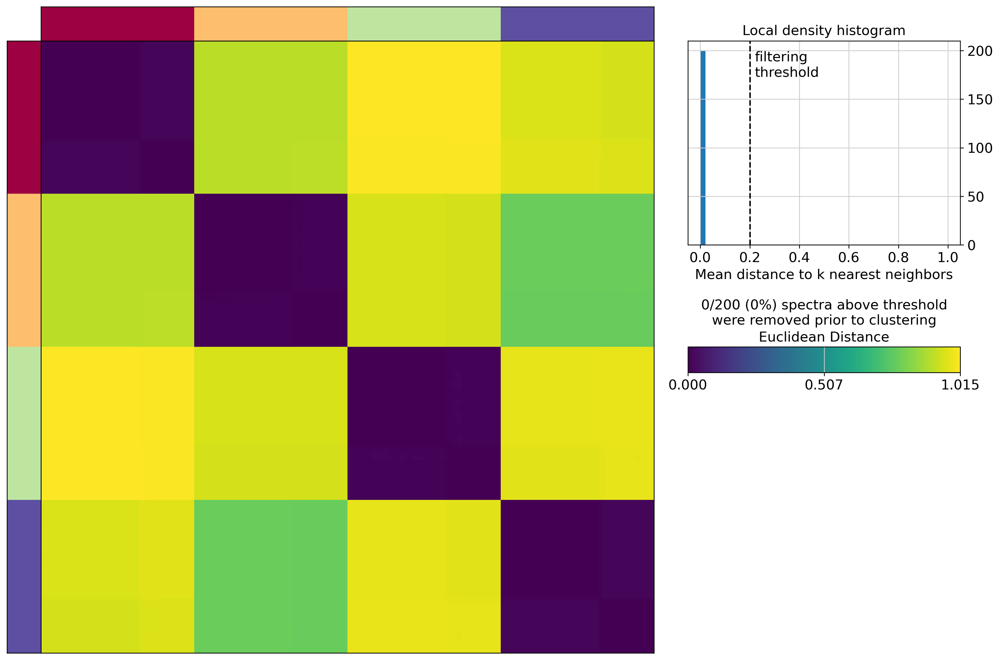

In [ ]:
# Generate consensus
k=4
density_threshold=0.2

cnmf_obj.consensus(k=k, density_threshold=density_threshold, show_clustering=True)

# Inspect the consensus plot
#consensus_plot_path = ''
#Image(filename = consensus_plot_path, width=800, height=600)

In [ ]:
# Load results
usage, spectra_scores, spectra_tpm, top_genes = cnmf_obj.load_results(K=k,density_threshold=density_threshold)

# Rename columns for clarity
usage.columns = ['GEP1','GEP2','GEP3','GEP4']
top_genes.columns = ['GEP1','GEP2','GEP3','GEP4']

# Import into adata
usage_aligned = usage.reindex(adata.obs_names)        # alignment to cell order in adata
adata.obsm["X_cnmf"] = usage_aligned.values           #
adata.obs[usage_aligned.columns] = usage_aligned      # per-topic columns in obs


In [ ]:
import pandas as pd
pd.set_option('display.max_columns', None)
top_genes.head(50)

,GEP1,GEP2,GEP3,GEP4
0,lrrfip1b,fn1a,pcxb,col14a1a
1,rmdn2,ror1,daam1a,inpp4b
2,LOC110437758,bmp16,tmem56b,si:dkey-172j4.3
3,tll1,ptprub,nrp1a,tcf7l1a
4,trip10a,lamc1,map7d2b,ntrk2a
5,plekhg5b,rap1gap,efnb3b,grb10b
6,tspan18b,mecom,bcl9l,ednraa
7,ralgps2,lmo1,cyp2aa9,slc7a8a
8,neurl1b,zgc:112994,acsl5,nme4
9,wapla,lamb1a,slc27a2a,acp5a


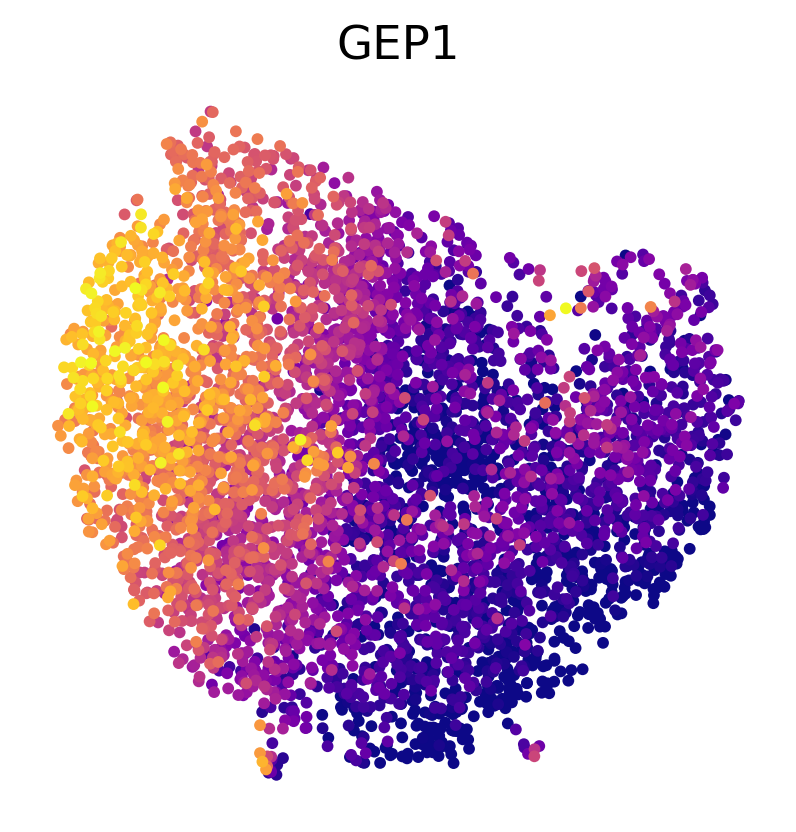

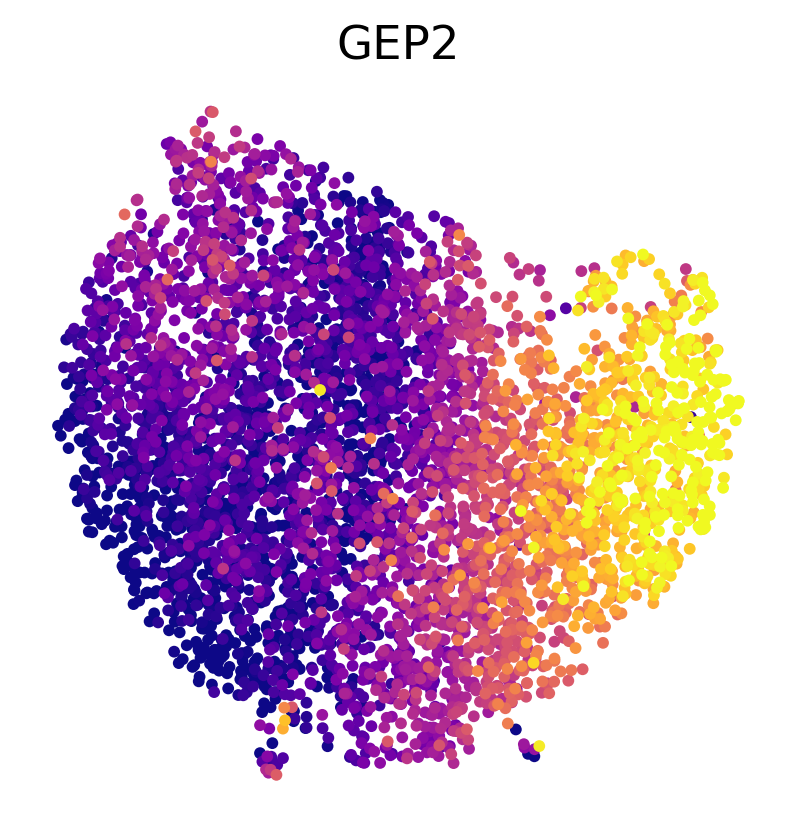

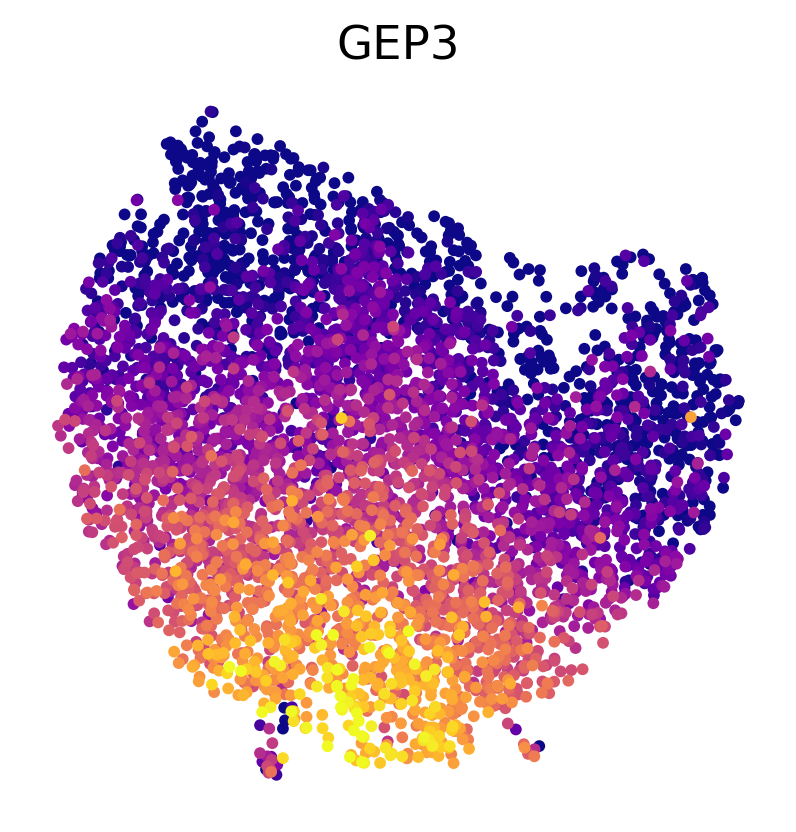

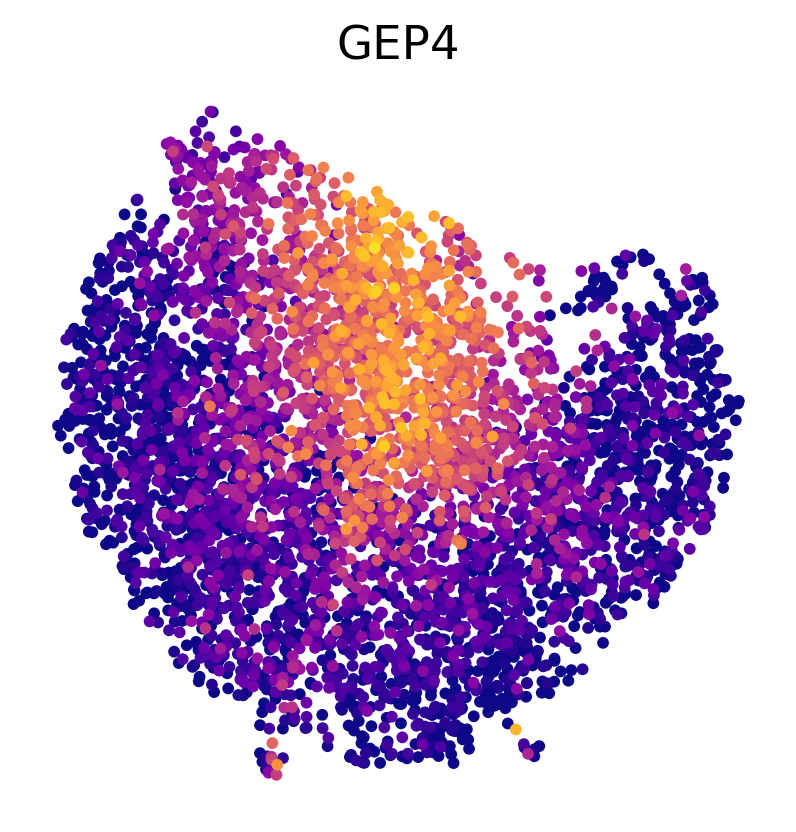

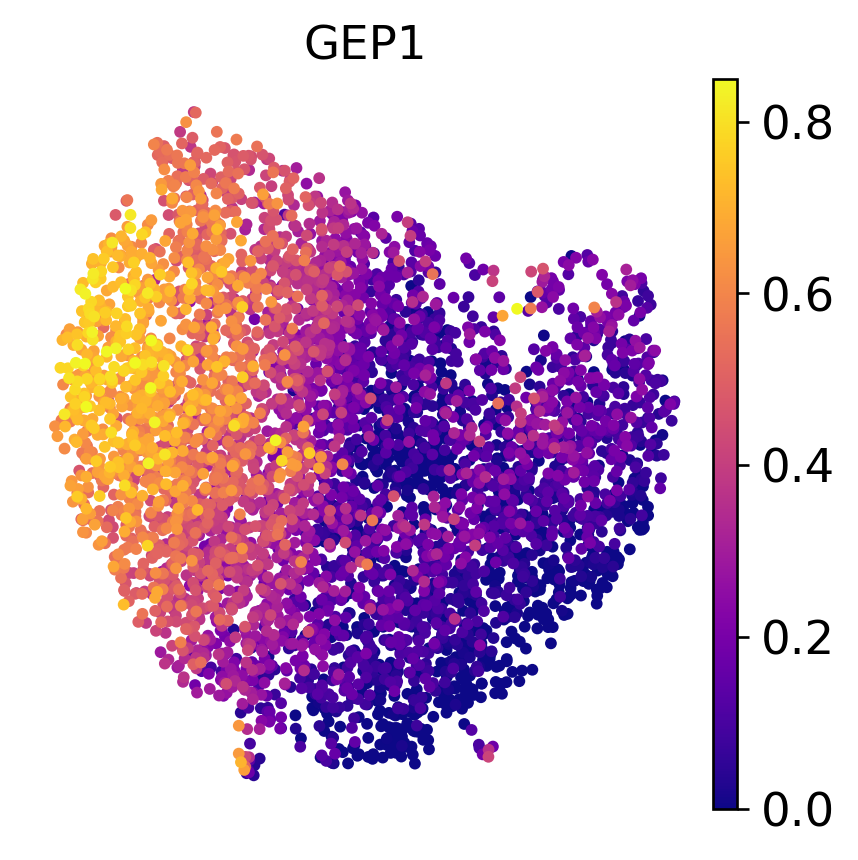

In [ ]:
sc.set_figure_params(figsize=(4, 4), dpi=120)
cmap='plasma'

f1 = sc.pl.umap(adata, s=50, frameon=False, color=['GEP1'], vmax=0.85, return_fig=True, cmap=cmap, colorbar_loc=None)
f2 = sc.pl.umap(adata, s=50, frameon=False, color=['GEP2'], vmax=0.85, return_fig=True, cmap=cmap, colorbar_loc=None)
f3 = sc.pl.umap(adata, s=50, frameon=False, color=['GEP3'], vmax=0.85, return_fig=True, cmap=cmap, colorbar_loc=None)
f4 = sc.pl.umap(adata, s=50, frameon=False, color=['GEP4'], vmax=0.85, return_fig=True, cmap=cmap, colorbar_loc=None)

f1.savefig(base_path+'figs/'+'YSL_subset_GEP1.png', dpi=200, bbox_inches="tight")
f2.savefig(base_path+'figs/'+'YSL_subset_GEP2.png', dpi=200, bbox_inches="tight")
f3.savefig(base_path+'figs/'+'YSL_subset_GEP3.png', dpi=200, bbox_inches="tight")
f4.savefig(base_path+'figs/'+'YSL_subset_GEP4.png', dpi=200, bbox_inches="tight")

f1 = sc.pl.umap(adata, s=50, frameon=False, color=['GEP1'], vmax=0.85, cmap=cmap, return_fig=True)
f1.savefig(base_path+'figs/'+'YSL_subset_GEP1.pdf', dpi=200, bbox_inches="tight")



## Save h5ad

In [ ]:
adata.write(base_path+'YSL-subset_pp_norm_processed.h5ad')

##